In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

df = pd.read_csv("/content/twitter.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Dataset shape: (31962, 3)


,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      31962 non-null  int64 
 1   label   31962 non-null  int64 
 2   tweet   31962 non-null  object
dtypes: int64(2), object(1)
memory usage: 749.2+ KB

Missing values:
id       0
label    0
tweet    0
dtype: int64

Duplicate records:
0


label
0    29720
1     2242
Name: count, dtype: int64


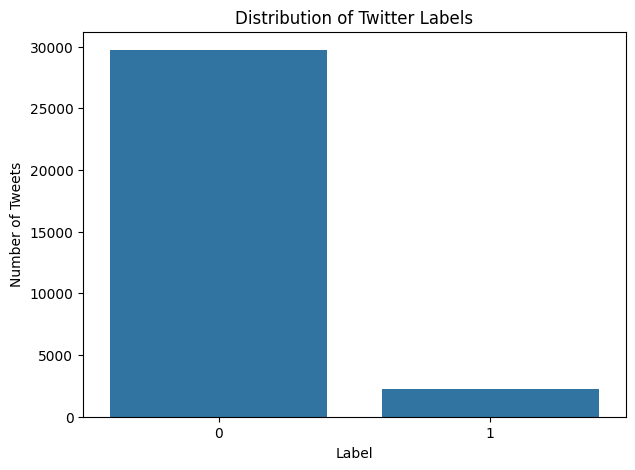

In [4]:
print(df["label"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Twitter Labels")
plt.xlabel("Label")
plt.ylabel("Number of Tweets")

plt.show()

In [5]:
print(
    df["label"].value_counts(normalize=True) * 100
)

label
0    92.98542
1     7.01458
Name: proportion, dtype: float64


In [6]:
df = df.dropna(subset=["tweet", "label"]).copy()

df = df.drop_duplicates()

def clean_tweet(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove user mentions
    text = re.sub(r"@\w+", "", text)

    # Remove HTML entities
    text = re.sub(r"&amp;", "and", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["clean_tweet"] = df["tweet"].apply(clean_tweet)

display(df[["tweet", "clean_tweet"]].head(10))

,tweet,clean_tweet
0,@user when a father is dysfunctional and is s...,when a father is dysfunctional and is so selfi...
1,@user @user thanks for #lyft credit i can't us...,thanks for lyft credit i can t use cause they ...
2,bihday your majesty,bihday your majesty
3,#model i love u take with u all the time in ...,model i love u take with u all the time in ur
4,factsguide: society now #motivation,factsguide society now motivation
5,[2/2] huge fan fare and big talking before the...,huge fan fare and big talking before they leav...
6,@user camping tomorrow @user @user @user @use...,camping tomorrow danny
7,the next school year is the year for exams.ð...,the next school year is the year for exams can...
8,we won!!! love the land!!! #allin #cavs #champ...,we won love the land allin cavs champions clev...
9,@user @user welcome here ! i'm it's so #gr...,welcome here i m it s so gr


In [7]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def remove_stopwords(text):

    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(words)

df["clean_tweet"] = df["clean_tweet"].apply(remove_stopwords)

display(df[["tweet", "clean_tweet"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,tweet,clean_tweet
0,@user when a father is dysfunctional and is s...,father dysfunctional selfish drags kids dysfun...
1,@user @user thanks for #lyft credit i can't us...,thanks lyft credit use cause offer wheelchair ...
2,bihday your majesty,bihday majesty
3,#model i love u take with u all the time in ...,model love u take u time ur
4,factsguide: society now #motivation,factsguide society motivation


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["clean_tweet"]
y = df["label"]

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

In [9]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = tfidf.fit_transform(X_train_text)

X_test = tfidf.transform(X_test_text)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25569, 10000)
Testing shape: (6393, 10000)


In [10]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb_model = MultinomialNB()

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

nb_model.fit(X_train, y_train)

lr_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

nb_predictions = nb_model.predict(X_test)

lr_predictions = lr_model.predict(X_test)

def evaluate_model(name, y_true, predictions):

    print("\n", name)

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Precision:",
          precision_score(y_true, predictions,
                          zero_division=0))

    print("Recall:",
          recall_score(y_true, predictions,
                       zero_division=0))

    print("F1 Score:",
          f1_score(y_true, predictions,
                   zero_division=0))

    print("\nClassification Report:")
    print(classification_report(
        y_true, predictions, zero_division=0
    ))

evaluate_model("Naive Bayes", y_test, nb_predictions)

evaluate_model("Logistic Regression", y_test, lr_predictions)


 Naive Bayes
Accuracy: 0.9516658845612389
Precision: 0.9793103448275862
Recall: 0.3169642857142857
F1 Score: 0.47892074198988194

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      5945
           1       0.98      0.32      0.48       448

    accuracy                           0.95      6393
   macro avg       0.97      0.66      0.73      6393
weighted avg       0.95      0.95      0.94      6393


 Logistic Regression
Accuracy: 0.9347724073205068
Precision: 0.5226939970717424
Recall: 0.796875
F1 Score: 0.6312997347480106

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96      5945
           1       0.52      0.80      0.63       448

    accuracy                           0.93      6393
   macro avg       0.75      0.87      0.80      6393
weighted avg       0.95      0.93      0.94      6393



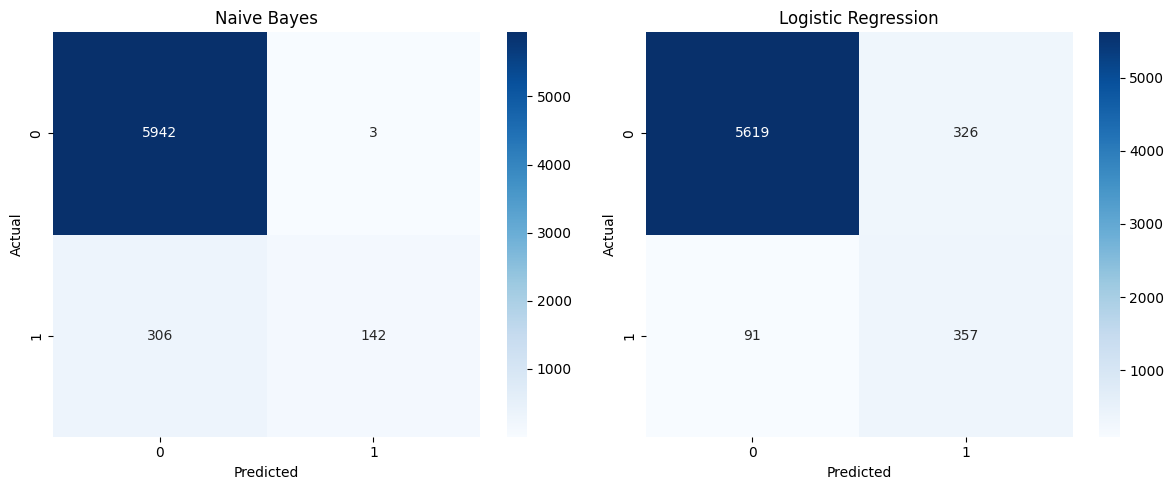

In [12]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models_predictions = [
    ("Naive Bayes", nb_predictions),
    ("Logistic Regression", lr_predictions)
]

for ax, (name, predictions) in zip(axes, models_predictions):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

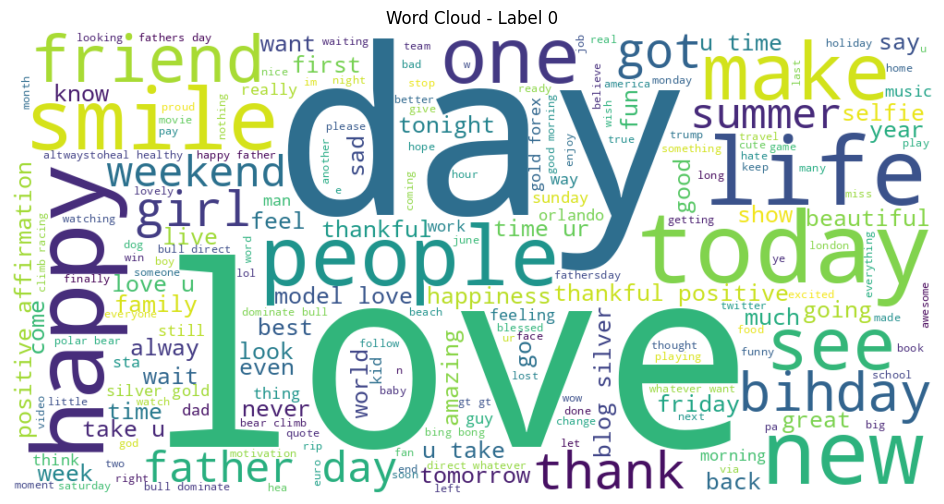

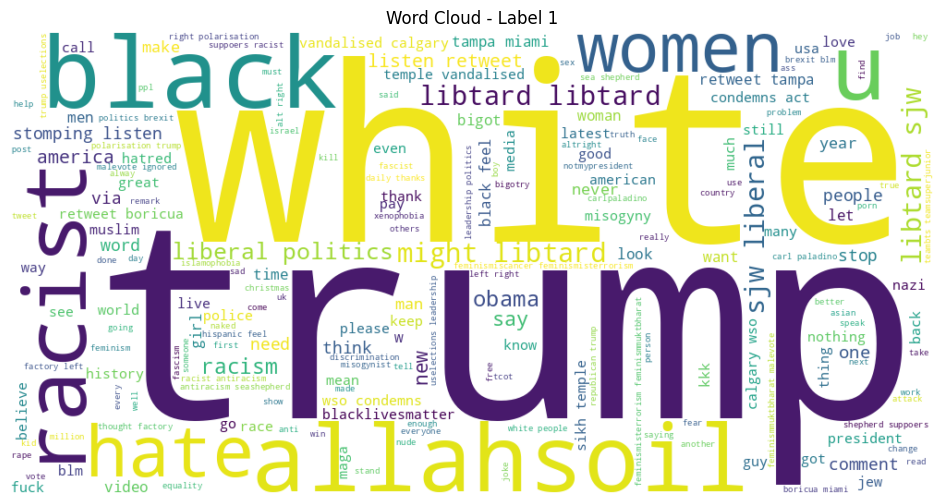

In [13]:
from wordcloud import WordCloud

for label in sorted(df["label"].unique()):

    text = " ".join(
        df.loc[df["label"] == label, "clean_tweet"]
    )

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white"
    ).generate(text)

    plt.figure(figsize=(12, 6))

    plt.imshow(wordcloud, interpolation="bilinear")

    plt.axis("off")

    plt.title(f"Word Cloud - Label {label}")

    plt.show()

In [14]:
results = pd.DataFrame({
    "Tweet": X_test_text.values,
    "Actual": y_test.values,
    "Predicted": lr_predictions
})

misclassified = results[
    results["Actual"] != results["Predicted"]
]

display(misclassified.head(5))

,Tweet,Actual,Predicted
5,gets,0,1
14,whole world knows potus anti american jihadina...,0,1
29,black walnut wooden picture horsehour woodcutw...,0,1
33,ya think bcause women r muslim c uncovered hea...,0,1
65,dear sirs please transfer shri pahlaj nihalani...,0,1


In [15]:
comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],

    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions)
    ],

    "Precision": [
        precision_score(y_test, nb_predictions,
                        zero_division=0),
        precision_score(y_test, lr_predictions,
                        zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, nb_predictions,
                     zero_division=0),
        recall_score(y_test, lr_predictions,
                     zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, nb_predictions,
                 zero_division=0),
        f1_score(y_test, lr_predictions,
                 zero_division=0)
    ]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.951666,0.979310,0.316964,0.478921
1,Logistic Regression,0.934772,0.522694,0.796875,0.631300


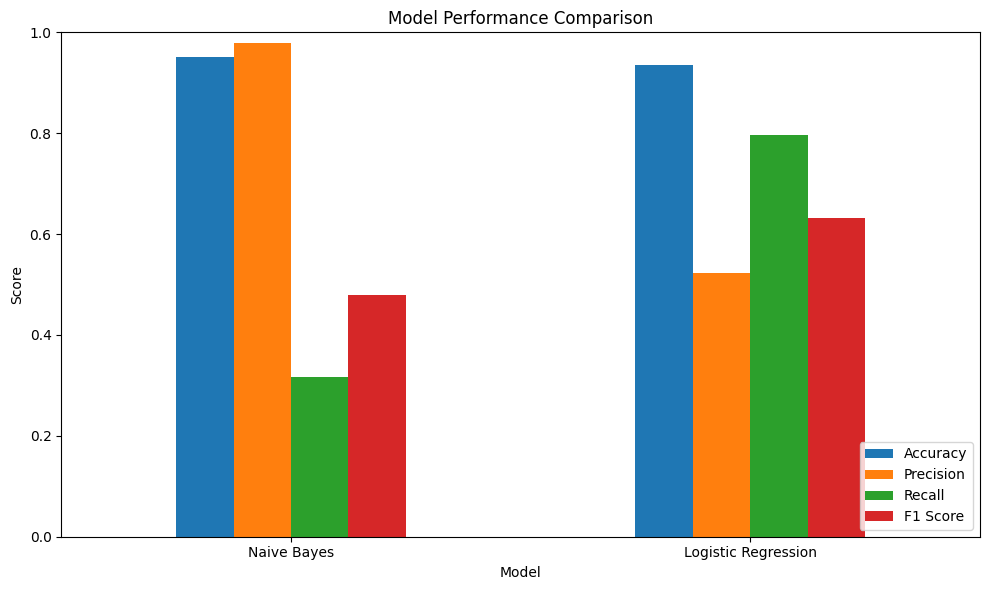

In [16]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()